# Normalizing Flows for Stellar Abundances

*Tutorial by Yuan-Sen Ting (ting.74@osu.edu)*

*Companion material for Chapter 15 of the textbook*

*If you find this tutorial useful, please cite the accompanying textbook.*

*[Statistical Machine Learning for Astronomy](https://ui.adsabs.harvard.edu/abs/2025arXiv250612230T/abstract)*

*© 2025 Yuan-Sen Ting. All rights reserved. This tutorial may be redistributed by sharing the original [website page link](https://tingyuansen.github.io/statml/) for educational purposes. Any other reproduction or adaptation requires explicit permission from the author.*

## Introduction

The elemental abundances of stars in the Milky Way form sequences. The ratios [Fe/H] and [Mg/Fe] are abundance ratios relative to the Sun. In their plane, the stars follow two curved sequences with a lower density between them.

The two sequences come from two kinds of supernovae. Massive stars explode soon after they form and make magnesium. The upper sequence holds stars enriched mainly by these explosions. Type Ia supernovae are explosions of white dwarfs in binary systems. The white dwarf gains mass from a companion, and the explosion occurs later and makes iron. The lower sequence holds stars whose gas also received this iron.

Surveys measure the abundances of many elements, and the abundances of one star form a point in a space with one dimension for each element. A model of the density in this space can generate mock stars and tell how typical a star is. The space has many dimensions, so the model needs many parameters, and we cannot check it by eye. The structure is also not simple. Already the plane of [Fe/H] and [Mg/Fe] shows two curved sequences, which a density with a fixed shape, such as a Gaussian, cannot follow.

A normalizing flow (Section 15.13) takes another route. An invertible neural network transforms a standard Gaussian into the density of the stars. The change of variables (Section 3.2) then gives the exact likelihood, so we can train the flow by maximum likelihood (Section 4.3).

We build the most basic flow, RealNVP (Real-valued Non-Volume Preserving), from scratch in PyTorch. A one-dimensional map shows how an invertible map changes a density. We then build coupling layers, which keep the map invertible and its Jacobian cheap to compute. We train the flow on the abundances of stars from APOGEE, a spectroscopic survey of the Milky Way. The sample follows [Ting & Weinberg (2022)](https://ui.adsabs.harvard.edu/abs/2022ApJ...927..209T/abstract). We check the samples of the flow against stars that we did not use for training.

## Prerequisites and Learning Objectives

### Prerequisites

This tutorial assumes the following.

- Neural networks, backpropagation and the basics of PyTorch (Chapter 15, Tutorial 15a)
- Training a network on a negative log-likelihood with Adam (Tutorial 15c)
- The transformation of random variables and the Jacobian determinant (Chapter 3)
- Maximum likelihood estimation, and training and test data (Chapter 4)
- The multivariate Gaussian (Chapter 2)

### Learning Objectives

After this tutorial you can do the following.

- Explain how a probability density changes under an invertible map, and the role of the Jacobian determinant
- Explain why a coupling layer is invertible and has a cheap Jacobian
- Build an invertible neural network from coupling layers
- Train a normalizing flow by maximum likelihood, stop at the lowest validation loss and generate samples with its inverse
- Compare the samples of a flow with test stars in several projections

We begin by importing the libraries and setting the plot style.

In [1]:
# Display matplotlib plots inline in the Jupyter notebook
%matplotlib inline

# Import the libraries
import copy
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader

# Set the plot style
plt.rcParams['figure.figsize'] = [10, 6]
plt.rcParams['font.size'] = 15
plt.rcParams['axes.labelsize'] = 15
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['xtick.labelsize'] = 15
plt.rcParams['ytick.labelsize'] = 15
plt.rcParams['legend.fontsize'] = 15
plt.rcParams['legend.frameon'] = False
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=['#3468A8', '#E49A3A', '#2E8B6E', '#C24A3E', '#6F5E9E', '#8A8A8A'])
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['DejaVu Serif'], 'mathtext.fontset': 'cm'})
plt.rcParams.update({'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True})

# Set the random seed for reproducibility
_ = torch.manual_seed(42)

## The Abundance Data

The data hold 13 abundances for each of 23,986 stars. The elements are Mg, O, Si, S, Ca, Na, Al, K, Cr, Fe, Ni, V and Co. The notation [X/H] is the logarithmic abundance ratio of the element X and hydrogen, relative to the Sun,

$$[\text{X/H}] = \log_{10}\left(\frac{N_{\text{X}}}{N_{\text{H}}}\right)_{\star} - \log_{10}\left(\frac{N_{\text{X}}}{N_{\text{H}}}\right)_{\odot},$$

where $N$ is the number density of atoms. A star with [Fe/H] = -1 has an iron to hydrogen ratio ten times lower than the Sun. Because the scale is logarithmic, the ratio [Mg/Fe] is [Mg/H] minus [Fe/H].

We split the stars at random into 60 percent training stars, 20 percent validation stars and 20 percent test stars (Section 4.7). The training stars fit the flow, the validation stars tell us when to stop the training, and the test stars check the result. The abundances have standard deviations of about 0.2 to 0.3, while the base Gaussian of a flow has unit width. We therefore standardize each abundance with the mean and the standard deviation of the training stars.

In [2]:
# Load the abundances [X/H] of the stars, with one column for each element
data = np.load('../data/dataset_apogee_abundances.npz')
x_all = data['abundances']
elements = list(data['elements'])
i_mg, i_fe = elements.index('Mg'), elements.index('Fe')

# Split the stars at random into 60 percent training, 20 percent validation and 20 percent test stars
rng = np.random.default_rng(42)
order = rng.permutation(len(x_all))  # a random order of the stars
n_train, n_val = int(0.6 * len(x_all)), int(0.2 * len(x_all))
train_idx = order[:n_train]
val_idx = order[n_train:n_train + n_val]
test_idx = order[n_train + n_val:]

# Standardize with the mean and the standard deviation of the training stars
x_mean = x_all[train_idx].mean(axis=0)
x_std = x_all[train_idx].std(axis=0)
x_train = (x_all[train_idx] - x_mean) / x_std
x_val = (x_all[val_idx] - x_mean) / x_std
x_test = (x_all[test_idx] - x_mean) / x_std
print(f"{len(x_train)} training stars, {len(x_val)} validation stars, {len(x_test)} test stars")
print(f"{x_all.shape[1]} abundances for each star")


14391 training stars, 4797 validation stars, 4798 test stars
13 abundances for each star


We look at the plane of [Fe/H] and [Mg/Fe]. Darker hexagons hold more points, on a logarithmic scale.

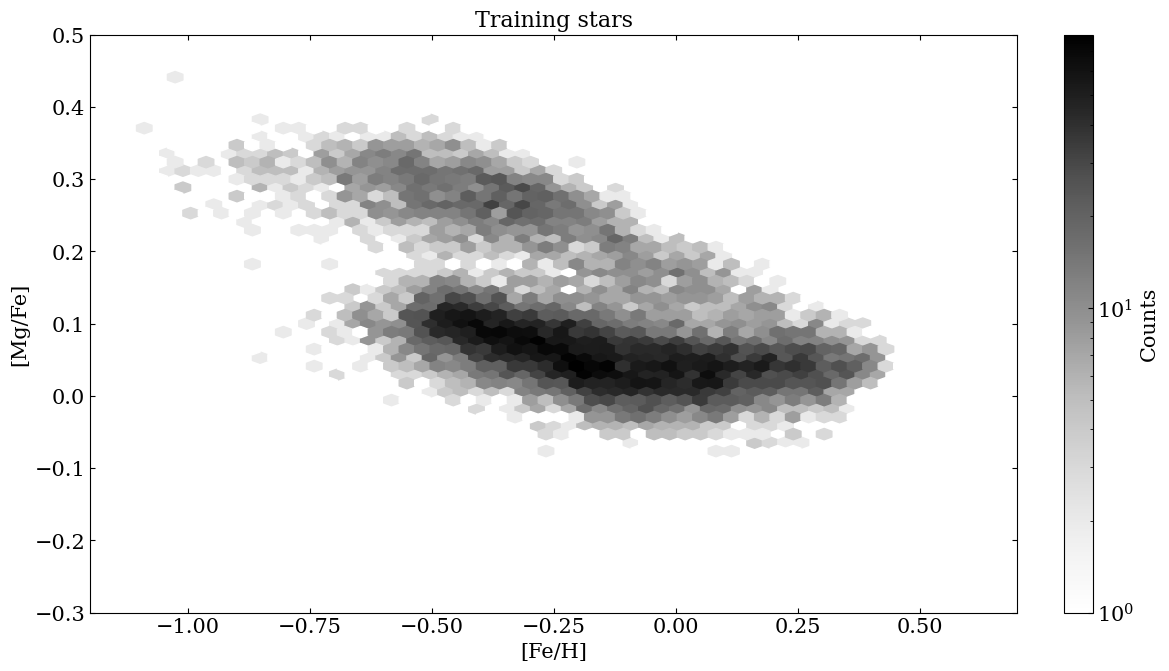

In [3]:
# Plot the density of stars or samples in the plane of [Fe/H] and [Mg/Fe]
def plot_plane(ax, abundances, title, vmax=None):
    # Hexagonal bins in grey, as in the book, darker for more points on a logarithmic scale
    hb = ax.hexbin(abundances[:, i_fe], abundances[:, i_mg] - abundances[:, i_fe],
                   gridsize=60, bins='log', vmin=1, vmax=vmax, mincnt=1, cmap='Greys',
                   extent=(-1.2, 0.7, -0.3, 0.5))
    ax.set_xlim(-1.2, 0.7)
    ax.set_ylim(-0.3, 0.5)
    ax.set_xlabel("[Fe/H]")
    ax.set_title(title)
    return hb

# The number of abundances, and the training stars in the plane of [Fe/H] and [Mg/Fe]
n_dim = x_train.shape[1]
fig, ax = plt.subplots(figsize=(11.6, 6.6), layout='constrained')
hb = plot_plane(ax, x_all[train_idx], 'Training stars')
ax.set_ylabel("[Mg/Fe]")
fig.colorbar(hb, ax=ax, label='Counts')
plt.show()


The stars form a dense lower sequence and a fainter upper sequence, with a lower density between them.

## The Basic Ideas of Normalizing Flows

A normalizing flow learns the density without a chosen parametric family. The idea has three parts. We choose a simple base density, a standard Gaussian. We learn an invertible map $f$ that carries a variable $\mathbf{z}$ with the base density to the data $\mathbf{x}$. The inverse map $f^{-1}$ carries the data back to $\mathbf{z}$.

Invertible means that every $\mathbf{z}$ gives one $\mathbf{x}$, and every $\mathbf{x}$ gives one $\mathbf{z}$. The two maps give us two abilities. To generate a new star, we draw $\mathbf{z}$ from the standard Gaussian and compute $\mathbf{x} = f(\mathbf{z})$. To evaluate the density of a star, we compute $\mathbf{z} = f^{-1}(\mathbf{x})$ and use the change of variables (Section 3.2),

$$p(\mathbf{x}) = p(\mathbf{z})\left|\det\left(\frac{\partial \mathbf{z}}{\partial \mathbf{x}}\right)\right| = p(f^{-1}(\mathbf{x}))\left|\det\left(\frac{\partial f^{-1}}{\partial \mathbf{x}}\right)\right|.$$

The determinant of the Jacobian matrix measures how $f^{-1}$ stretches space. If $f^{-1}$ maps a region of $\mathbf{x}$ to a larger region of $\mathbf{z}$, $p(\mathbf{x})$ is higher than $p(\mathbf{z})$. Both regions hold the same probability.

The logarithm of $p(\mathbf{x})$ is the log-likelihood of a star. We train the map by maximizing the mean log-likelihood of the training stars, so the loss is minus this mean. The loss needs $f^{-1}$ and the determinant of its Jacobian for every star at every step.

## A Flow in One Dimension

In one dimension we know such a map already, from the inverse CDF method (Section 12.3). Let $F$ be the cumulative distribution function (CDF) of $x$, and let $\Phi$ be the CDF of the standard Gaussian. For $x$ drawn from the density, the number $u = F(x)$ is uniform between 0 and 1, and $z = \Phi^{-1}(u)$ is a standard Gaussian. The map

$$z = f^{-1}(x) = \Phi^{-1}(F(x))$$

therefore carries any density to the standard Gaussian. It is invertible, because the CDFs increase everywhere and so each $x$ gives one $z$. Its inverse, $x = f(z) = F^{-1}(\Phi(z))$, generates samples of $x$. In many dimensions this method has difficulties, so a flow learns the map with a neural network. Before that, we check the density formula in one dimension with a map that we can write down, the sigmoid function.

We start from a standard Gaussian $z$ and map it with the sigmoid function

$$x = f(z) = \frac{1}{1 + e^{-2z}}.$$

This map is invertible, because it increases at every $z$. Its derivative $\mathrm{d}x/\mathrm{d}z = 2x(1-x)$ is positive for every $x$ between 0 and 1, so each $x$ comes from exactly one $z$. Solving for $z$ gives the inverse map, the logit function divided by 2,

$$z = f^{-1}(x) = \frac{1}{2}\ln\frac{x}{1-x}.$$

In one dimension the Jacobian determinant is the derivative of $f^{-1}$,

$$\frac{\mathrm{d}f^{-1}}{\mathrm{d}x} = \frac{1}{2x(1-x)}.$$

We draw 100,000 samples of $z$, map them to $x$ with the sigmoid function and map them back with its inverse, the logit function. The curve in the middle panel is the density $p(f^{-1}(x))\,|\mathrm{d}f^{-1}/\mathrm{d}x|$ that the change of variables gives. The curves in the other two panels are the standard Gaussian density.

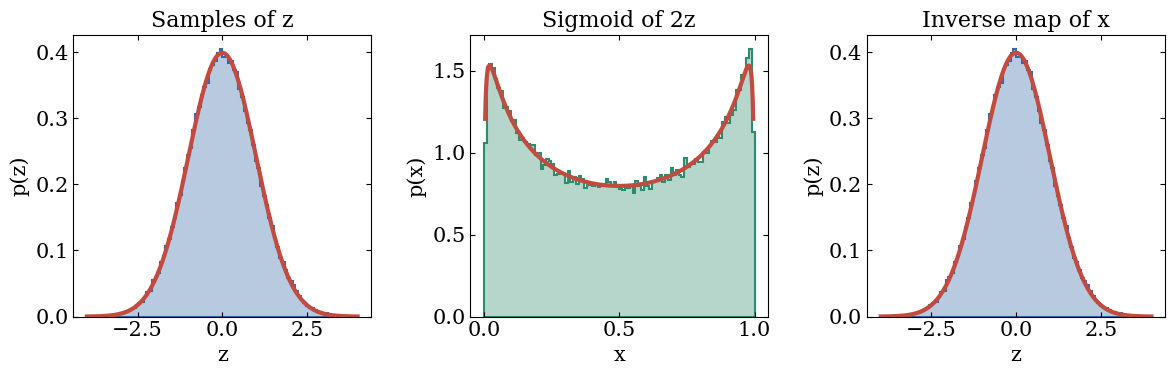

In [4]:
# The sigmoid map x = f(z), its inverse z = f^-1(x) and the standard Gaussian density
def sigmoid_map(z):
    return 1 / (1 + torch.exp(-2 * z))

def logit_map(x):
    return 0.5 * torch.log(x / (1 - x))

def standard_normal_pdf(z):
    return torch.exp(-0.5 * z**2) / math.sqrt(2 * math.pi)

# Draw samples of a standard Gaussian z, map them to x, and map them back
z = torch.randn(100000)
x = sigmoid_map(z)
z_back = logit_map(x)

# Density of x from the change of variables, p(f^-1(x)) |df^-1/dx|, with df^-1/dx = 1 / [2 x (1 - x)]
x_grid = torch.linspace(0.005, 0.995, 500)
p_x = standard_normal_pdf(logit_map(x_grid)) / (2 * x_grid * (1 - x_grid))

# The standard Gaussian density, for the two panels of z
z_range = torch.linspace(-4, 4, 200)
p_z = standard_normal_pdf(z_range)

# Plot the three densities
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].hist(z.numpy(), bins=100, range=(-4, 4), density=True,
             histtype='stepfilled', facecolor=('C0', 0.35), edgecolor='C0', linewidth=1.5)
axes[0].plot(z_range, p_z, '-', color='C3', lw=3)
axes[0].set_xlabel("z")
axes[0].set_ylabel("p(z)")
axes[0].set_title("Samples of z")
axes[1].hist(x.numpy(), bins=100, range=(0, 1), density=True,
             histtype='stepfilled', facecolor=('C2', 0.35), edgecolor='C2', linewidth=1.5)
axes[1].plot(x_grid, p_x, '-', color='C3', lw=3)
axes[1].set_xlabel("x")
axes[1].set_ylabel("p(x)")
axes[1].set_title("Sigmoid of 2z")
axes[2].hist(z_back.numpy(), bins=100, range=(-4, 4), density=True,
             histtype='stepfilled', facecolor=('C0', 0.35), edgecolor='C0', linewidth=1.5)
axes[2].plot(z_range, p_z, '-', color='C3', lw=3)
axes[2].set_xlabel("z")
axes[2].set_ylabel("p(z)")
axes[2].set_title("Inverse map of x")
plt.tight_layout()
plt.show()

The left panel shows the standard Gaussian. The sigmoid map turns it into a density with two peaks, one near 0 and one near 1. The curve from the change of variables follows the histogram. The inverse map recovers the standard Gaussian in the right panel. We can therefore describe a complex density through its relation to a simple one.

## The Two Requirements

In this example we chose the map. For the abundances we do not know a map to a Gaussian, so we learn it with a neural network. The network must meet two requirements.

It must be invertible, so that we can map $\mathbf{x}$ to $\mathbf{z}$ for the density and $\mathbf{z}$ to $\mathbf{x}$ for sampling. A general ReLU network does not meet this. A ReLU sets all negative inputs to 0, so two different stars can give the same output.

The Jacobian determinant must also be cheap to compute. The loss needs it for every star at every step, and the determinant of a general $D \times D$ matrix needs $O(D^3)$ operations. We therefore need a design in which both requirements hold by construction (Section 15.13).

## Introducing RealNVP

RealNVP ([Dinh et al. 2016](https://ui.adsabs.harvard.edu/abs/2016arXiv160508803D/abstract)) meets both requirements with coupling layers. A layer keeps some dimensions fixed and transforms the others with a map that depends on the fixed ones. The fixed dimensions pass through unchanged, so one layer cannot transform every dimension. We therefore stack several layers, and each layer fixes different dimensions.

We write a layer in the direction from the data $\mathbf{x}$ to the base $\mathbf{z}$, which is the direction of $f^{-1}$. Take two abundances, $x_1$ for [Fe/H] and $x_2$ for [Mg/Fe]. We leave $x_1$ unchanged, which we call freezing it, and we transform $x_2$ by a one-dimensional map, a stretch and a shift,

$$z_1 = x_1, \qquad z_2 = x_2\, e^{s(x_1)} + t(x_1).$$

The numbers $s$ and $t$ depend on $x_1$, and they come from two neural networks. For each fixed $x_1$, the map from $x_2$ to $z_2$ is a straight line with the positive slope $e^{s}$. A line with a positive slope is a simple invertible map in one dimension. The exponential keeps the slope positive for any output of the network. Because the networks see $x_1$, the line changes with $x_1$. The map can then stretch and shift [Mg/Fe] differently at low and at high [Fe/H], as the two sequences require.

Both requirements hold by construction. For the inverse, the first equation gives $x_1 = z_1$. With $x_1$ known, we run the networks forward to get $s(x_1)$ and $t(x_1)$, and we solve the line for $x_2$,

$$x_2 = \big(z_2 - t(x_1)\big)\, e^{-s(x_1)}.$$

We never invert a neural network. For the Jacobian, $z_1$ does not depend on $x_2$, so the Jacobian matrix is lower triangular,

$$\mathbf{J} = \begin{bmatrix} 1 & 0 \\ \partial z_2/\partial x_1 & e^{s(x_1)} \end{bmatrix}, \qquad \ln|\det\mathbf{J}| = s(x_1).$$

The determinant is the product of the diagonal, so we never need the entry $\partial z_2/\partial x_1$, which holds the derivatives of the networks. This is why the layer fixes one dimension. The networks can be as complicated as we like.

A coupling layer does the same in $D$ dimensions. It freezes $d$ of the $D$ dimensions and transforms the other $D-d$ dimensions, based on the frozen ones. For simple notation we write the frozen dimensions first,

$$\mathbf{z}_{1:d} = \mathbf{x}_{1:d},$$

$$\mathbf{z}_{d+1:D} = \mathbf{x}_{d+1:D} \odot \exp(s(\mathbf{x}_{1:d})) + t(\mathbf{x}_{1:d}).$$

The subscripts select dimensions, and $\odot$ is the element-wise product. The scale $s$ and the shift $t$ are neural networks that map $\mathbb{R}^d$ to $\mathbb{R}^{D-d}$. The name Non-Volume Preserving refers to $\exp(s)$, which changes volumes, while a shift alone preserves them.

The same two properties hold in $D$ dimensions. The layer is invertible for three reasons.

1. **Coupling structure.** One group of dimensions stays unchanged, and the other group is transformed.
2. **Algebraic invertibility.** The transformation of the second group is a scale and a shift, which we invert algebraically.
3. **No inversion of the networks.** We only evaluate the networks $s$ and $t$, and we never invert them.

The Jacobian is cheap for three reasons.

1. **Triangular structure.** The frozen dimensions do not change, so the Jacobian matrix is triangular.
2. **Diagonal determinant.** The determinant of a triangular matrix is the product of its diagonal elements.
3. **Efficient computation.** This reduces an $O(D^3)$ operation to an $O(D)$ operation.

In the code, a binary mask picks the frozen dimensions, so that we need not reorder the data. The networks $s$ and $t$ then map $\mathbb{R}^D$ to $\mathbb{R}^D$. We multiply the input by the mask, so that the networks see only the frozen dimensions. We multiply their output by one minus the mask, so that only the other dimensions change.

## Constructing a RealNVP from Scratch

The equations are short, but a layer has several steps. We build one layer for $D = 5$ inputs, with the first $d = 2$ dimensions frozen, and we print each step.

The networks $s$ and $t$ are multilayer perceptrons (MLPs) with three hidden layers and ReLU activations (Section 15.5). The class `MLP` builds the network with `nn.Sequential`, which applies its layers one after the other. It maps $D$ values to $D$ values. This is more general than the equations, where $s$ and $t$ map $d$ values to $D-d$ values. We create one network for $s$ and one for $t$, with 64 neurons in each hidden layer. We fix the seed, so that this example does not depend on the earlier cells.

In [5]:
# Multilayer perceptron with three hidden layers, which maps n_in values to n_in values
class MLP(nn.Module):
    def __init__(self, n_in, n_hidden):
        super().__init__()

        # nn.Sequential applies the listed layers one after the other
        self.net = nn.Sequential(
            nn.Linear(n_in, n_hidden), nn.ReLU(),
            nn.Linear(n_hidden, n_hidden), nn.ReLU(),
            nn.Linear(n_hidden, n_hidden), nn.ReLU(),
            nn.Linear(n_hidden, n_in))

    def forward(self, x):
        return self.net(x)

# The networks s and t of a layer with five inputs, with the seed fixed
_ = torch.manual_seed(42)
s_network = MLP(5, 64)
t_network = MLP(5, 64)

A mask selects the frozen dimensions. Here the mask is $(1, 1, 0, 0, 0)$, and the inverse mask, one minus the mask, is $(0, 0, 1, 1, 1)$. We multiply a random input by the mask and feed the result to the network $s$. We then multiply the output of the network by the inverse mask.

In [6]:
# The mask freezes the first two of five dimensions, and the inverse mask selects the other three
mask = torch.tensor([1., 1., 0., 0., 0.])
inverse_mask = 1 - mask

# A random input, and the input with the transformed dimensions set to 0
x = torch.randn(1, 5)
x_frozen = x * mask
print("x:", x[0].numpy().round(3))
print("x times the mask:", x_frozen[0].numpy().round(3) + 0.0)

# The network s sees only the frozen dimensions, and the inverse mask keeps its output for the other dimensions
s = s_network(x_frozen) * inverse_mask
print("s:", s[0].detach().numpy().round(3) + 0.0)

x: [-0.605 -0.149 -0.785 -0.048 -0.884]
x times the mask: [-0.605 -0.149  0.     0.     0.   ]
s: [ 0.     0.    -0.132  0.104  0.111]


The mask sets the last three numbers of the input to 0 and keeps the first two. The network $s$ therefore sees only the first two dimensions, because the other inputs are always 0. The inverse mask keeps the output of the network for the last three dimensions and sets the output for the first two to 0. An MLP that maps $\mathbb{R}^D$ to $\mathbb{R}^D$ then acts as the map from $\mathbb{R}^d$ to $\mathbb{R}^{D-d}$ of the equations.

We compute the shift $t$ in the same way. Then we scale and shift the last three dimensions of the input.

In [7]:
# The shift, and the scaled and shifted transformed dimensions
t = t_network(x_frozen) * inverse_mask
z_transformed = x * inverse_mask * torch.exp(s) + t
print("t:", t[0].detach().numpy().round(3) + 0.0)
print("Transformed dimensions:", z_transformed[0].detach().numpy().round(3) + 0.0)

t: [ 0.     0.    -0.08  -0.067 -0.093]
Transformed dimensions: [ 0.     0.    -0.768 -0.121 -1.081]


The frozen dimensions pass through unchanged. The two masks do not overlap, so the output $\mathbf{z}$ is the sum of the frozen part and the transformed part.

In [8]:
# The output of the layer, the frozen dimensions plus the transformed dimensions
z = x_frozen + z_transformed
print("z:", z[0].detach().numpy().round(3))

z: [-0.605 -0.149 -0.768 -0.121 -1.081]


The first two numbers of $\mathbf{z}$ equal those of $\mathbf{x}$, and the other three change. We use these steps again for every layer, so we write them once as a function, which maps $\mathbf{x}$ to $\mathbf{z}$ for one layer.

In [9]:
# Map of one coupling layer from the data x to the base z, with the networks s_network and t_network
def to_base(x, mask):
    x_frozen = x * mask
    s = s_network(x_frozen) * (1 - mask)
    t = t_network(x_frozen) * (1 - mask)
    return x_frozen + (x * (1 - mask) * torch.exp(s) + t)

## Inverting RealNVP

Sampling needs the inverse map from $\mathbf{z}$ to $\mathbf{x}$. It follows the two-dimensional case. The frozen dimensions are unchanged, so $\mathbf{x}_{1:d} = \mathbf{z}_{1:d}$. We solve the second equation for the other dimensions,

$$\mathbf{x}_{d+1:D} = (\mathbf{z}_{d+1:D} - t(\mathbf{z}_{1:d})) \odot \exp(-s(\mathbf{z}_{1:d})).$$

The networks take the frozen dimensions as input, and these are the same in $\mathbf{x}$ and $\mathbf{z}$. We therefore run $s$ and $t$ forward and invert the scale and the shift algebraically. We train $s$ and $t$ with standard forward passes and backpropagation, and the inverse needs no extra training. The networks can have any architecture.

We write the inverse of one layer as a function, like the map to the base.

In [10]:
# Map of one coupling layer from the base z to the data x, with s and t evaluated on the frozen dimensions of z
def to_data(z, mask):
    z_frozen = z * mask
    s = s_network(z_frozen) * (1 - mask)
    t = t_network(z_frozen) * (1 - mask)
    return z_frozen + (z * (1 - mask) - t) * torch.exp(-s)

## The Jacobian of RealNVP

The second requirement is a cheap Jacobian determinant. The change of variables needs its logarithm (Section 3.2),

$$\ln p(\mathbf{x}) = \ln p(\mathbf{z}) + \ln\left|\det\left(\frac{\partial \mathbf{z}}{\partial \mathbf{x}}\right)\right|.$$

As in the two-dimensional case, the Jacobian matrix of a coupling layer is

$$\mathbf{J} = \frac{\partial \mathbf{z}}{\partial \mathbf{x}} = \begin{bmatrix} \mathrm{Id}_{d} & \mathbf{0}_{d \times (D-d)} \\ \frac{\partial \mathbf{z}_{d+1:D}}{\partial \mathbf{x}_{1:d}} & \text{diag}(\exp(s(\mathbf{x}_{1:d}))) \end{bmatrix}.$$

This is a lower-triangular block matrix, so its determinant is the product of its diagonal elements. The lower-left block does not enter,

$$\det(\mathbf{J}) = \prod_{j=d+1}^{D} \exp(s(\mathbf{x}_{1:d}))_j = \exp\left(\sum_{j=d+1}^{D} s(\mathbf{x}_{1:d})_j\right).$$

We work with the logarithm, which is stable numerically and is a sum,

$$\ln|\det(\mathbf{J})| = \sum_{j=d+1}^{D} s(\mathbf{x}_{1:d})_j.$$

We do not compute a $D \times D$ determinant. We only sum the outputs of the network $s$, an $O(D)$ operation.

We extend the map to the base so that it also returns the sum of $s$.

In [11]:
# The map of one coupling layer to the base that also returns the log-determinant of the Jacobian, the sum of s
def to_base_log_det(x, mask):
    x_frozen = x * mask
    s = s_network(x_frozen) * (1 - mask)
    t = t_network(x_frozen) * (1 - mask)
    z = x_frozen + (x * (1 - mask) * torch.exp(s) + t)
    return z, s.sum(dim=1)

## The Coupling Layer in PyTorch

A flow needs many layers, each with its own mask and its own networks, so we pack the steps into a class. The class holds the mask and the two networks. It computes $s$ and $t$, maps $\mathbf{x}$ to $\mathbf{z}$ and returns the sum of $s$, and maps $\mathbf{z}$ to $\mathbf{x}$. The sum of $s$ is the log-determinant, because $s$ is zero for the frozen dimensions. The method `register_buffer` stores the mask with the layer, and training does not change it. The parameters of the flow are then the weights of the networks only.


In [12]:
# One coupling layer, which freezes the dimensions where the mask is 1
class CouplingLayer(nn.Module):
    def __init__(self, mask, n_hidden):
        super().__init__()

        # The layer stores the mask, and training does not change it
        self.register_buffer('mask', mask)
        self.s_net = MLP(len(mask), n_hidden)
        self.t_net = MLP(len(mask), n_hidden)

    def scale_shift(self, frozen):
        # The networks see only the frozen dimensions, and the inverse mask keeps the outputs of the other dimensions
        s = self.s_net(frozen) * (1 - self.mask)
        t = self.t_net(frozen) * (1 - self.mask)
        return s, t

    def forward(self, x):
        # Map x to z and return the log-determinant of the Jacobian, the sum of s
        frozen = x * self.mask
        s, t = self.scale_shift(frozen)
        z = frozen + (x * (1 - self.mask) * torch.exp(s) + t)
        return z, s.sum(dim=1)

    def inverse(self, z):
        # Map z to x, with s and t evaluated on the frozen dimensions of z
        frozen = z * self.mask
        s, t = self.scale_shift(frozen)
        return frozen + (z * (1 - self.mask) - t) * torch.exp(-s)

## The Coupling Strategy

In one layer, the frozen dimensions never change, so one layer cannot reshape the whole density. We therefore stack several layers and change which dimensions are frozen. Let $h_1$ freeze the dimensions 1 to $d$, and let $h_2$ freeze the other dimensions. Both layers map the data toward the base. The map $f^{-1}$ and its inverse $f$ are

$$f^{-1} = h_2 \circ h_1, \qquad f = h_1^{-1} \circ h_2^{-1},$$

so $f$ applies the inverse layers in reverse order. The Jacobian matrices multiply by the chain rule, so the determinants multiply and the log-determinants add,

$$\ln|\det(\mathbf{J}_{f^{-1}})| = \ln|\det(\mathbf{J}_{h_1})| + \ln|\det(\mathbf{J}_{h_2})|.$$

Each layer adds one cheap term.

Our flow stacks 8 layers in 4 pairs, and each pair is like $h_1$ and $h_2$. In each pair, the first layer freezes a random set of 6 of the 13 abundances, and the second layer freezes the other 7. The two masks of a pair are opposite, so each pair transforms every abundance exactly once. Every abundance is then transformed by exactly 4 of the 8 layers.

The flow class keeps the layers in an `nn.ModuleList`, which registers them so that their parameters train. It maps $\mathbf{x}$ to $\mathbf{z}$ by running the layers in order, and it maps $\mathbf{z}$ to $\mathbf{x}$ by running the inverse layers in reverse order. It also computes the log-density,

$$\ln p(\mathbf{x}) = \ln p(\mathbf{z}) + \ln|\det(\mathbf{J})|.$$

The base density $p(\mathbf{z})$ is a standard Gaussian in $D$ dimensions, the product of $D$ standard Gaussians,

$$\ln p(\mathbf{z}) = -\frac{1}{2}\sum_{j=1}^{D} z_j^2 - \frac{D}{2}\ln 2\pi.$$

In [13]:
# A RealNVP flow is a stack of coupling layers
class RealNVP(nn.Module):
    def __init__(self, masks, n_hidden):
        super().__init__()

        # The ModuleList registers the layers, so that their parameters train
        self.layers = nn.ModuleList([CouplingLayer(mask, n_hidden) for mask in masks])

    def to_base(self, x):
        # The map f^-1 from the data x to the base z, with the sum of the log-determinants of the layers
        log_det = torch.zeros(x.shape[0])
        for layer in self.layers:
            x, layer_log_det = layer(x)
            log_det = log_det + layer_log_det
        return x, log_det

    def to_data(self, z):
        # The map f from the base z to the data x, through the layers in reverse order
        for layer in reversed(self.layers):
            z = layer.inverse(z)
        return z

    def log_prob(self, x):
        # ln p(x) = ln p(z) + ln|det J|, with a standard Gaussian p(z)
        z, log_det = self.to_base(x)
        log_base = -0.5 * (z**2).sum(dim=1) - 0.5 * z.shape[1] * math.log(2 * math.pi)
        return log_base + log_det


We create the flow with 8 layers and 128 neurons in each hidden layer of $s$ and $t$. The masks come in pairs. We fix the seed again, so that the masks and the initial weights do not depend on the earlier cells.

In [14]:
# Opposite masks in pairs of layers, with a random choice of the 6 frozen abundances
mask_rng = np.random.default_rng(42)
masks = []
for _ in range(4):
    pair_mask = torch.zeros(n_dim)

    # A random set of 6 abundances is frozen in the first layer of the pair
    pair_mask[torch.tensor(mask_rng.permutation(n_dim)[:n_dim // 2])] = 1
    masks += [pair_mask, 1 - pair_mask]

# Each row is the mask of one layer, with 1 for a frozen abundance
print(torch.stack(masks).int().numpy())  # torch.stack joins the masks into one matrix

# Create the flow, with the seed fixed so that the weights do not depend on the earlier cells
_ = torch.manual_seed(42)
flow = RealNVP(masks, n_hidden=128)
print(f"The flow has {sum(p.numel() for p in flow.parameters())} parameters.")

[[1 0 0 1 0 0 0 1 0 1 1 0 1]
 [0 1 1 0 1 1 1 0 1 0 0 1 0]
 [0 0 1 0 1 1 0 1 0 0 1 0 1]
 [1 1 0 1 0 0 1 0 1 1 0 1 0]
 [0 1 0 0 1 0 1 1 1 0 0 0 1]
 [1 0 1 1 0 1 0 0 0 1 1 1 0]
 [0 1 0 0 0 1 1 0 1 1 0 1 0]
 [1 0 1 1 1 0 0 1 0 0 1 0 1]]
The flow has 583888 parameters.


Each row is the mask of one layer. The rows come in pairs of opposite masks. Every column has four zeros, so each abundance is transformed by four layers.

## Training the Flow

We train the flow by maximum likelihood (Section 4.3). The loss is the negative log-likelihood, averaged over the training stars. We minimize it with the Adam optimizer (Section 15.3) on mini-batches of 512 stars. An epoch is one pass through the training stars. The learning rate decays along a cosine curve from $3 \times 10^{-4}$ to $10^{-5}$ over 150 epochs.

A flow can fit the noise of the training stars. We therefore train all 150 epochs, compute the loss of the validation stars after every epoch, and select the epoch with the lowest validation loss. This is early stopping (Section 15.3), and we keep the weights of the selected epoch. The test stars take no part in this choice.

In [15]:
# Convert the standardized stars to PyTorch tensors
x_train_t = torch.tensor(x_train, dtype=torch.float32)
x_val_t = torch.tensor(x_val, dtype=torch.float32)
x_test_t = torch.tensor(x_test, dtype=torch.float32)

# Adam with a learning rate that decays along a cosine curve over the epochs, once per epoch
n_epochs, batch_size = 150, 512
optimizer = torch.optim.Adam(flow.parameters(), lr=3e-4)

# The scheduler lowers the rate from 3e-4 to 1e-5 along a cosine curve over the 150 epochs
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs, eta_min=1e-5)
train_loader = DataLoader(x_train_t, batch_size, shuffle=True)

# The loss of the training and the validation stars at each epoch, and the weights of the best epoch
train_losses, val_losses = [], []
best_val_loss = float('inf')
for epoch in range(1, n_epochs + 1):
    # One update for each mini-batch of training stars
    for batch in train_loader:
        # Negative log-likelihood of the mini-batch
        loss = -flow.log_prob(batch).mean()

        # Reset the gradients, then compute them by backpropagation
        optimizer.zero_grad()
        loss.backward()

        # Update the weights
        optimizer.step()

    # Lower the learning rate along the cosine curve
    scheduler.step()

    # The mean negative log-likelihood of all training stars and of all validation stars at the weights of this epoch
    with torch.no_grad():
        train_losses.append(-flow.log_prob(x_train_t).mean().item())  # all training stars
        val_losses.append(-flow.log_prob(x_val_t).mean().item())  # all validation stars

    # Keep a copy of the weights when the validation loss is the lowest so far
    if val_losses[-1] < best_val_loss:
        best_val_loss, best_epoch = val_losses[-1], epoch
        best_weights = copy.deepcopy(flow.state_dict())

# Go back to the weights of the epoch with the lowest validation loss, and print the loss of the test stars
flow.load_state_dict(best_weights)
with torch.no_grad():
    test_loss = -flow.log_prob(x_test_t).mean().item()  # all test stars
print(f"Lowest validation loss {best_val_loss:.3f} at epoch {best_epoch}, test loss {test_loss:.3f}")


Lowest validation loss -4.767 at epoch 54, test loss -4.751


We plot the loss of the training stars and of the validation stars at every epoch.

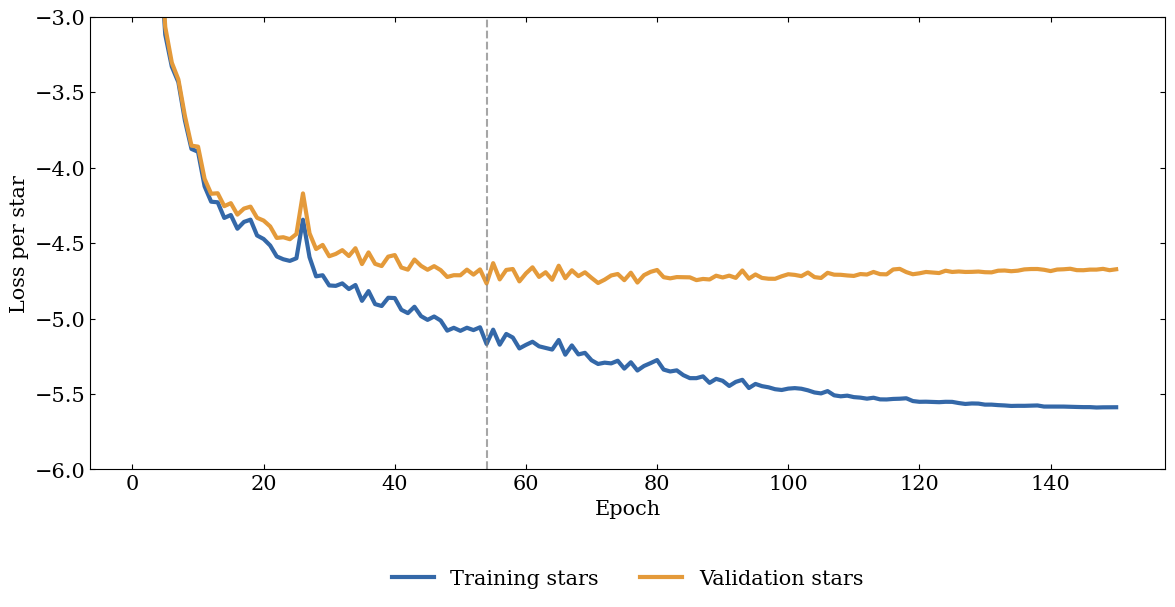

In [16]:
# The losses of the training and the validation stars at each epoch
epochs = np.arange(1, n_epochs + 1)
fig, ax = plt.subplots(figsize=(12.0, 6.4))
ax.plot(epochs, train_losses, linewidth=3, label='Training stars')
ax.plot(epochs, val_losses, linewidth=3, label='Validation stars')

# Mark the epoch with the lowest validation loss
ax.axvline(best_epoch, color='gray', linestyle='--', alpha=0.7)
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss per star')
ax.set_ylim(-6, -3)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2)
plt.tight_layout()
plt.show()


The training loss keeps falling to the end, while the validation loss stops falling at about epoch 50 and stays near $-4.7$. Its lowest value is at epoch 54, and it rises slowly to $-4.67$ at epoch 150. The gap between the two losses grows to about 0.9 per star. The flow fits the training stars better than new stars, which is overfitting. More epochs do not help, so we keep the weights of epoch 54, which is early stopping (Section 15.3). The test loss at these weights is $-4.751$, so the test log-likelihood of the flow is 4.751 per star.

## Samples from the Flow

So far we used the flow to evaluate densities. It also generates stars. To generate stars, we draw $\mathbf{z}$ from the standard Gaussian, apply the map $f$ and undo the standardization. The flow describes all 13 abundances. We look first at the plane of [Fe/H] and [Mg/Fe], and then at other projections. We generate as many samples as there are test stars and compare them with the test stars.

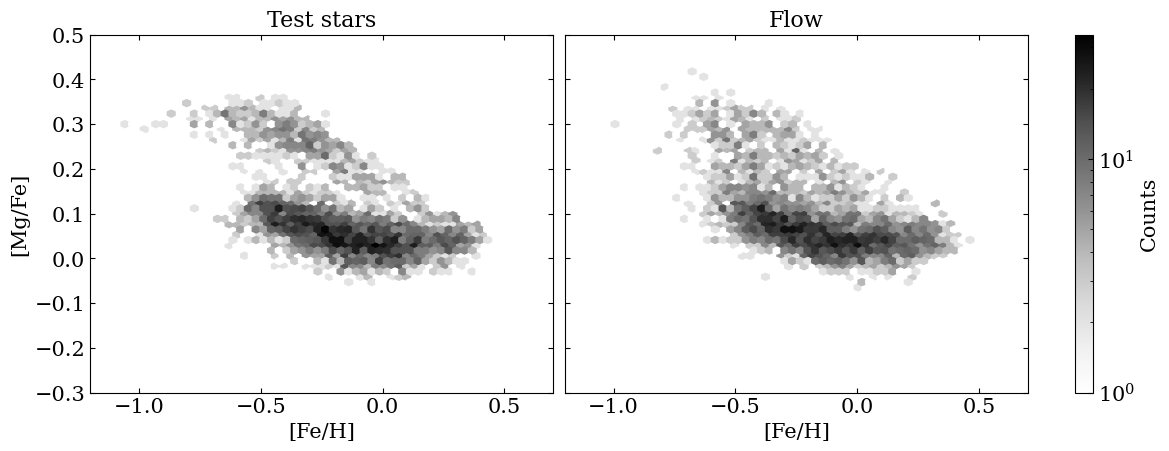

In [17]:
# Draw samples of the flow, with the map f from the base to the data, and undo the standardization
with torch.no_grad():
    flow_samples = flow.to_data(torch.randn(len(x_test), n_dim)).numpy() * x_std + x_mean

# Plot the test stars and the samples with one color scale
fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.4), sharey=True, layout='constrained')
panels = [(x_all[test_idx], 'Test stars'), (flow_samples, 'Flow')]
vmax = None
for ax, (abundances, title) in zip(axes, panels):
    hb = plot_plane(ax, abundances, title, vmax)
    if vmax is None:
        vmax = hb.get_array().max()
axes[0].set_ylabel("[Mg/Fe]")
fig.colorbar(hb, ax=axes, label='Counts')
plt.show()

The samples of the flow follow the structure of the stars in this plane, the two sequences with a lower density between them. They also fill part of the gap between the sequences, so the density is not yet as sharp as that of the stars. A normalizing flow must keep every layer invertible with a cheap Jacobian. RealNVP is the most basic design that meets this, and it limits how sharp the density can become. More expressive flows exist, and methods such as flow matching free the network from the invertibility constraint (Section 15.13).

The plane shows only two of the 13 dimensions, so the test log-likelihood is the more complete comparison.

## The Other Abundances

The flow models the 13 abundances together, so we look at other projections. We plot [X/Fe] against [Fe/H] for the other 12 elements. The grey density shows the flow samples of the previous section, without the hexagons that hold fewer than 3 samples. The red contours enclose 50, 80 and 95 percent of the test stars.

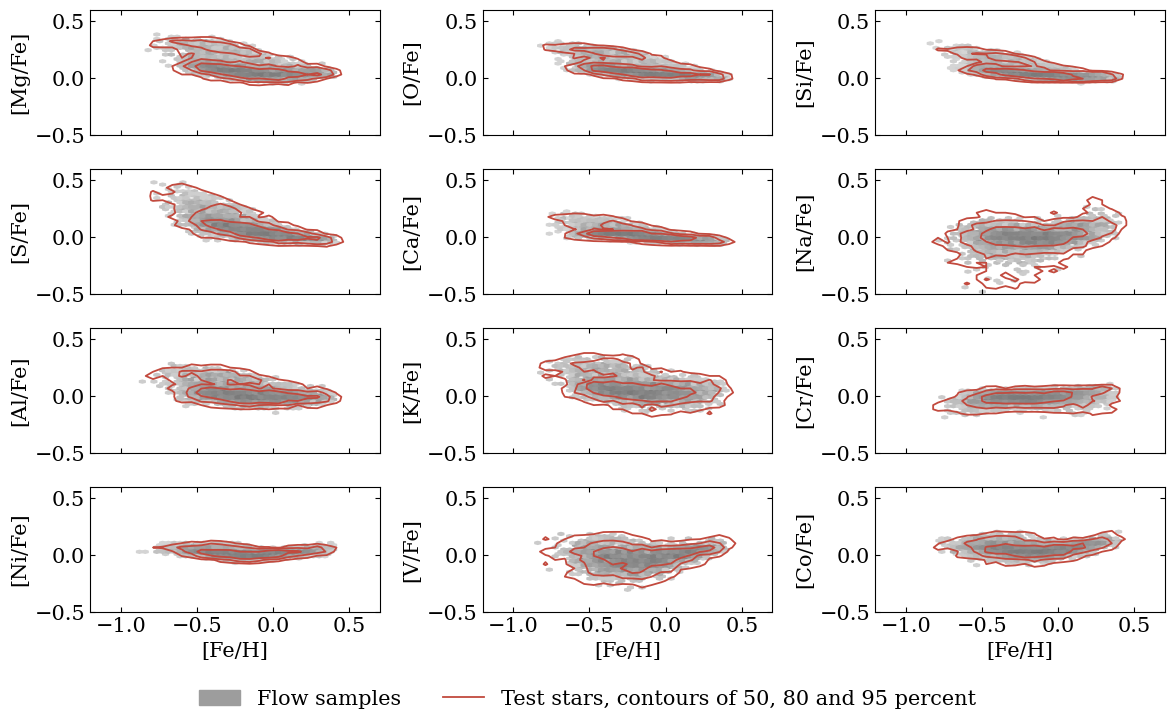

In [18]:
# Light greys for the flow samples, so that the red contours stand out
density_cmap = plt.matplotlib.colors.ListedColormap(plt.cm.Greys(np.linspace(0, 0.6, 256)))

# Plot [X/Fe] against [Fe/H] for the 12 elements other than Fe
fig, axes = plt.subplots(4, 3, figsize=(12, 7.4), sharex=True)
extent = (-1.2, 0.7, -0.5, 0.6)
test_stars = x_all[test_idx]
for ax, element in zip(axes.flatten(), [e for e in elements if e != 'Fe']):
    j = elements.index(element)

    # Flow samples as a density, with the hexagons of fewer than 3 samples left out and an extent that keeps rare outliers from stretching them
    ax.hexbin(flow_samples[:, i_fe], flow_samples[:, j] - flow_samples[:, i_fe],
              gridsize=50, bins='log', vmin=0.2, mincnt=3, cmap=density_cmap, extent=extent)

    # Contours of the test stars in a 30 x 30 histogram, at the counts that enclose 50, 80 and 95 percent of the stars
    counts, x_edges, y_edges = np.histogram2d(test_stars[:, i_fe], test_stars[:, j] - test_stars[:, i_fe], bins=30,
                                              range=((extent[0], extent[1]), (extent[2], extent[3])))

    # The counts of the bins from large to small, and the fraction of the stars in the bins up to each count
    sorted_counts = np.sort(counts.ravel())[::-1]
    enclosed = np.cumsum(sorted_counts) / counts.sum()

    # The counts where this fraction reaches 50, 80 and 95 percent are the levels of the contours
    levels = np.unique([sorted_counts[np.searchsorted(enclosed, fraction)] for fraction in (0.5, 0.8, 0.95)])

    # The centers of the bins, for the contour function
    x_centers = 0.5 * (x_edges[:-1] + x_edges[1:])
    y_centers = 0.5 * (y_edges[:-1] + y_edges[1:])
    ax.contour(x_centers, y_centers, counts.T, levels=levels, colors='C3', linewidths=1.3)
    ax.set_xlim(-1.2, 0.7)
    ax.set_ylim(-0.5, 0.6)
    ax.set_ylabel(f"[{element}/Fe]")
for ax in axes[-1]:
    ax.set_xlabel("[Fe/H]")

# One legend below the panels, for the flow samples and the contours of the stars
handles = [plt.Rectangle((0, 0), 1, 1, color=density_cmap(0.8)), plt.Line2D([0], [0], color='C3', linewidth=1.3)]
fig.legend(handles, ['Flow samples', 'Test stars, contours of 50, 80 and 95 percent'], loc='lower center', ncol=2, bbox_to_anchor=(0.5, 0.0))
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()


The density of the flow and the contours of the stars overlap in all 12 projections. For [Mg/Fe], [O/Fe] and [Si/Fe], the stars form two sequences, and the density follows both. For the other elements, the stars form one band or one cloud, and the density covers it.

## Summary

A normalizing flow models a density with an invertible neural network. Our main lessons follow.

1. **Exact density and sampling.** An invertible map between a standard Gaussian and the data gives the density of the data through the change of variables. The map itself generates new data.
2. **Invertibility and a cheap Jacobian.** The loss needs the density, so the map must be invertible. Its Jacobian determinant must also be cheap for every star at every step. A general neural network meets neither, so a flow restricts the architecture.
3. **Coupling layers.** A coupling layer freezes some dimensions and scales and shifts the others with networks of the frozen ones. The inverse is algebraic, and the Jacobian is triangular, so its log-determinant is a sum. One layer leaves the frozen dimensions unchanged, so we stack layers with different frozen dimensions. The log-determinants of the layers add.
4. **Limited expressiveness.** A coupling layer is a restricted map, and the samples of our flow still fill part of the gap between the sequences. More expressive flows, and flow-based methods such as flow matching, relax the restriction (Section 15.13).
5. **Overfitting and early stopping.** The training loss keeps falling while the validation loss stops falling and then rises slightly. Early stopping keeps the weights with the lowest validation loss, and the test stars give the final log-likelihood.

An invertible neural network extends the use of neural networks from point predictions to density estimation. It gives the exact likelihood of each object and generates mock objects. It is also a basis for simulation-based inference, where neural density estimators learn likelihoods and posteriors from simulations (Section 15.14).